# HW01

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Lab00 – NIfTI CT 영상 비교

In [29]:
import nibabel as nib

In [34]:
h = nib.load('volume-covid19-A-0700_day000.nii.gz')
print(h.shape)

(512, 512, 70)


In [36]:
ct_base = h.get_fdata()
print(ct_base.dtype, ct_base.shape)
print(np.min(ct_base),np.max(ct_base))

float64 (512, 512, 70)
-5363.0 30689.0


- day015 및 day015를 day000에 registration한 파일을 각각 불러오기.
- day000을 포함하여 세 ct영상데이터의 동일한 단면을 display하여 비교하기.

In [27]:
ct_FU = nib.load('volume-covid19-A-0700_day015.nii.gz').get_fdata()
ct_FU_reg = nib.load('volume-covid19-A-0700_day015_reg_to_day000.nii.gz').get_fdata()

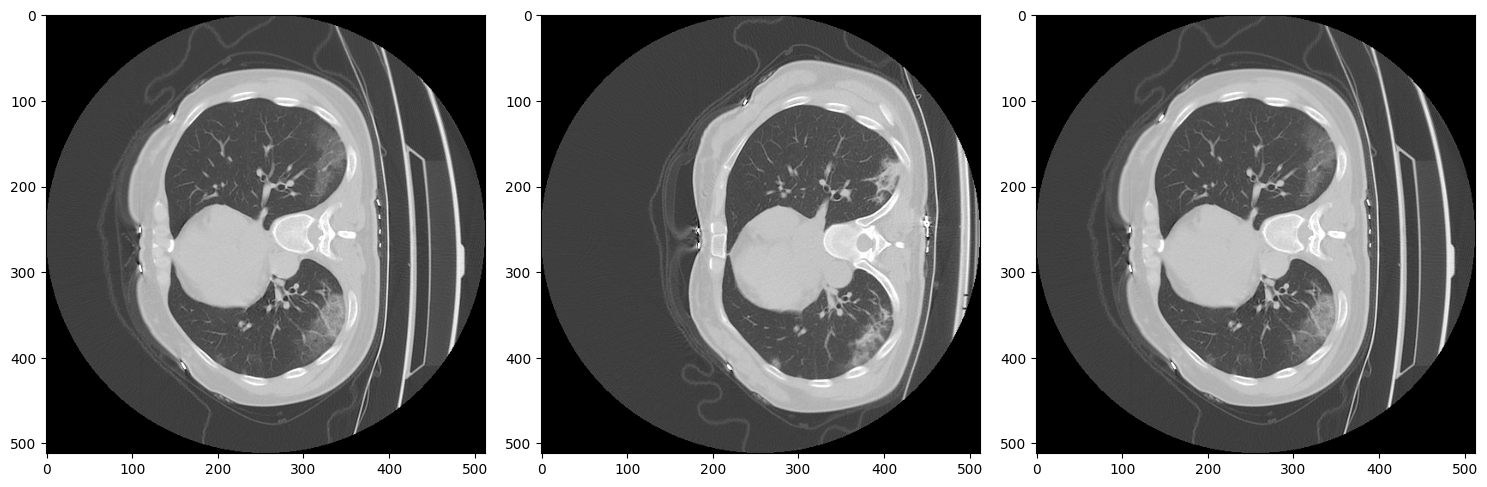

In [38]:
plt.figure(figsize=(15,5))
plt.subplot(131)
plt.imshow(ct_base[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(132)
plt.imshow(ct_FU[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(133)
plt.imshow(ct_FU_reg[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.tight_layout()
plt.show()

## Lab02 – Linear Filtering

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os
imgpath = '/content/drive/MyDrive/DIP4E'
os.listdir(imgpath)


In [16]:
def histogram_equalization(image):
    histogram, bins = np.histogram(image.flatten(), bins=256, range=[0,256])
    cdf = histogram.cumsum()
    cdf_min = cdf.min()
    cdf_max = cdf.max()
    cdf_normalized = (cdf - cdf_min) * 255 / (cdf_max - cdf_min)
    cdf_normalized = cdf_normalized.astype(np.uint8)
    equalized_image = cdf_normalized[image]
    return equalized_image

In [22]:
import scipy.signal as signal
from skimage import io

In [31]:
f = plt.imread(imgpath+'/hidden-symbols.tif')
print(f.shape,f.dtype)

(256, 256) uint8


### Exercise 1.
- 아래의 예는 local histogram equalization을 수행한다.
- 적절한 neighborhood size N을 찾아서 숨겨진 기호들을 모두 확인해보자.
- plt.imshow의 vim, vmax를 수정하여서도 숨겨진 기호들을 확인할 수 있으나, 본 실습에서는 vmax=255로 고정하여 histogram processing을 통해 숨겨진 기호들을 확인하자.

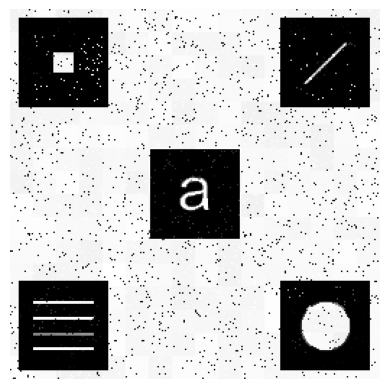

In [48]:
N = 16
f_eq_local = np.zeros_like(f)
for x in np.arange(0,256,N):
  for y in np.arange(0,256,N):
    f_eq_local[x:x+N,y:y+N] = histogram_equalization(f[x:x+N,y:y+N])

plt.imshow(f_eq_local,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

# 초기 N 값이 256 이고 이미지 크기가 256 * 256 이기 때문에 새 N을 256의 약수로 잡으면 모든 블록이
# 같은 크기로 딱 나누어 떨어져 가장자리에 크기가 다른 블록이 생기지않을 것 같다고 판단했다.
# N=256(영상 전체를 한 번에 처리)에서 시작해 128, 64, 32, 16, 8 순으로 줄여가며 결과를 비교했다.
# N이 클 때(128, 64, 32)는 숨겨진 기호가 잘 드러나지 않았다.
# N이 작을 때(8)는 화면이 지저분해져 기호를 알아보기 어려웠다.
# N=16일 때 숨겨진 기호들이 가장 잘 보여서 N=16으로 정했다.


### Exercise 2.
- 직접 찍은 사진을 grayscale image로 불러와서, kernel size를 3x3, 7x7, 15x15, 30x30 으로 늘려가며 box kernel을 정의하여 LPF를 진행한 결과를 출력하고 kernel size에 따른 연산시간의 차이를 확인하자.

In [52]:
f = io.imread('/content/red_panda.png',as_gray=True)
print(f.shape,f.dtype)

(1117, 738) float64


In [53]:
import time

computation time =  0.04533100128173828  sec


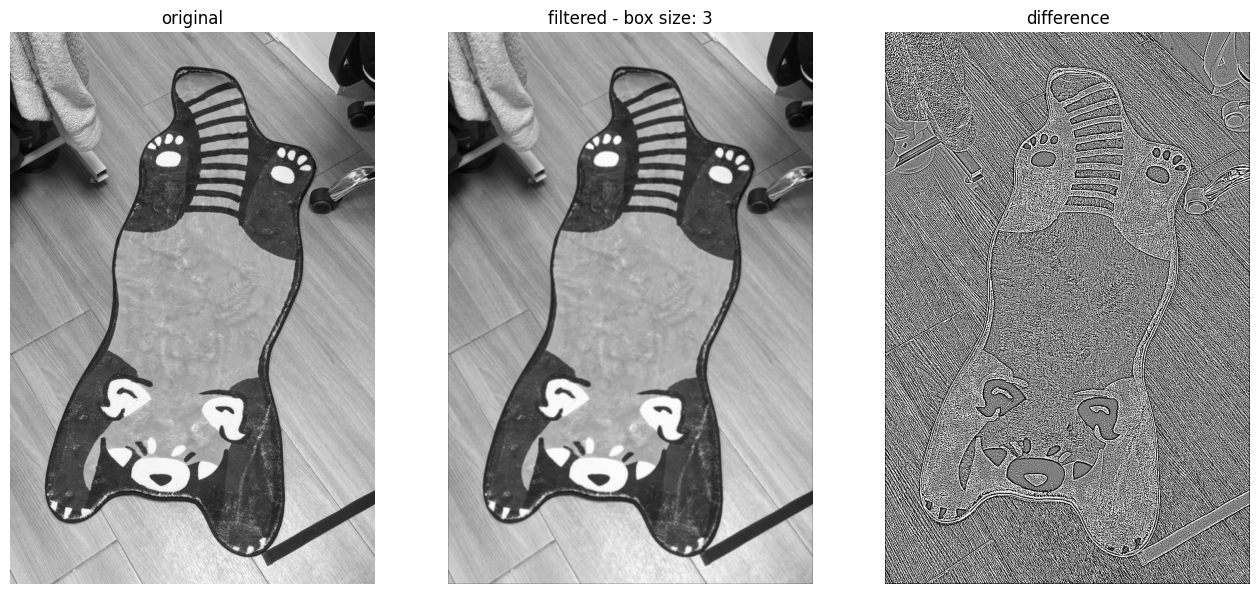

computation time =  0.16480350494384766  sec


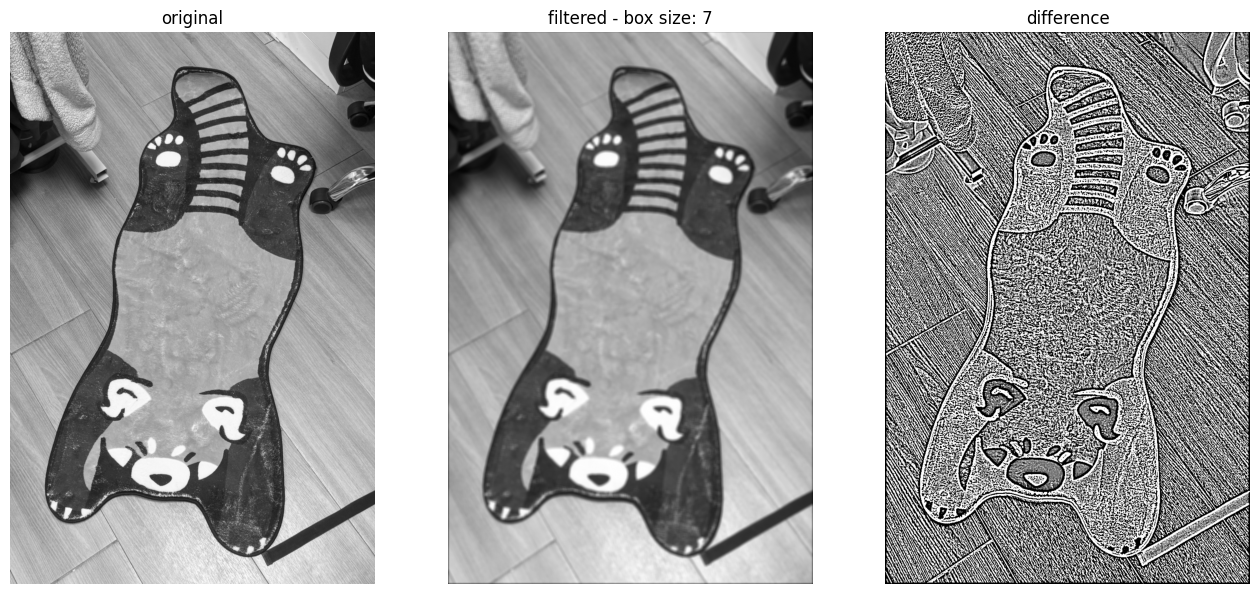

computation time =  0.515383243560791  sec


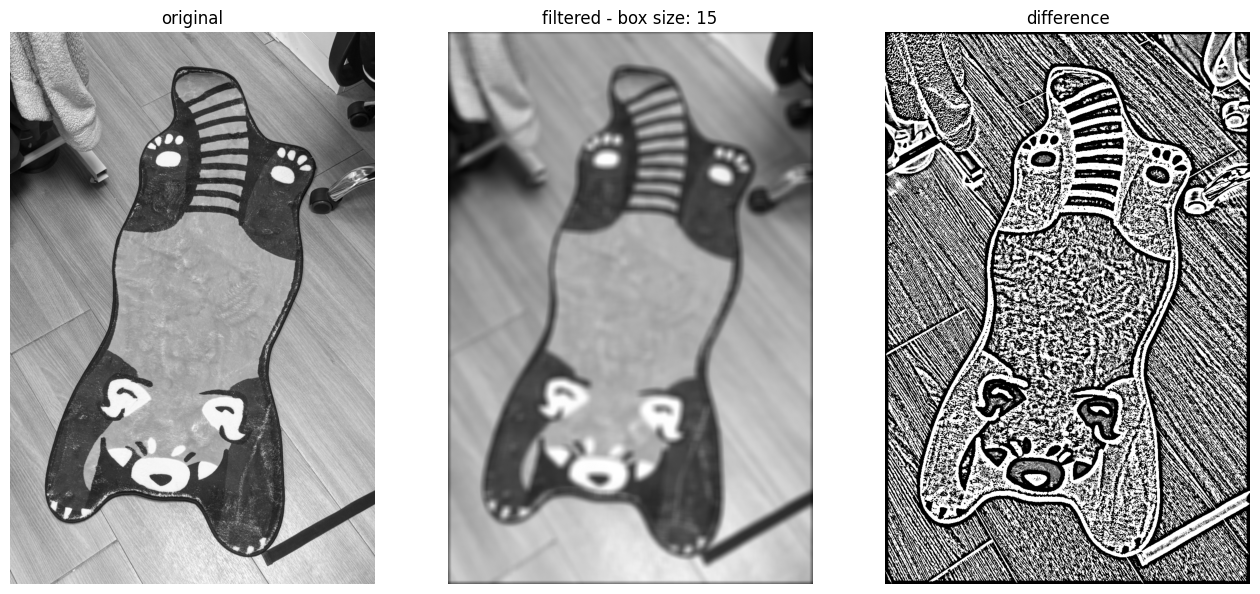

computation time =  1.8952879905700684  sec


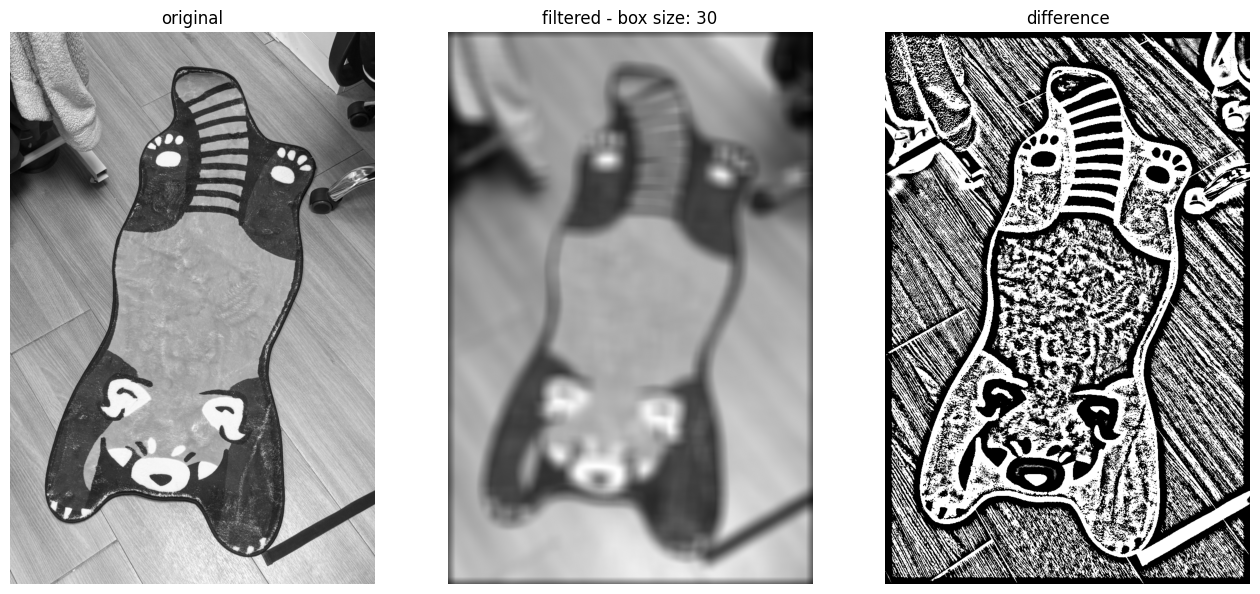

In [55]:
# 연산 시간: N이 커질수록 계산 시간이 눈에 띄게 늘어났다.
# 필터 크기가 N×N이라 한 픽셀을 계산할 때 더하는 값의 개수가 N²만큼 늘어나기 때문이라고 생각했다.
# (3×3은 9개, 30×30은 900개)
# filtered : N이 커질수록 사진이 점점 더 뿌옇게 흐려졌고, 작은 디테일과 선명한 경계가 사라졌다.
# 한 픽셀을 더 넓은 주변 영역의 평균으로 바꾸기 때문이라고 판단했다.
# difference : N이 커질수록 물체의 윤곽선이 더 굵고 진하게 나타났다.
# 평평한 부분은 흐려도 거의 변하지 않고, 밝기가 급하게 바뀌는 경계에서 차이가 크게 생기는 것으로 보인다.
# 가장자리: N이 커질수록 사진 테두리가 어두워지는 범위도 넓어졌다.
# 영상 바깥을 경계를 0으로 채우는 zero padding 방식이라서,
# 가장자리 픽셀의 평균에 0이 섞여 들어가기 때문이라고 판단했다. 커널이 클수록 0이 섞이는 범위도 넓어진다.

for N in np.array([3,7,15,30]):
  wb = np.ones((N,N))
  wb = wb/np.sum(wb)
  s0 = time.time()
  y_b = signal.convolve2d(f,wb,mode='same')
  compu_time=time.time() - s0
  print('computation time = ', compu_time,' sec')
  plt.figure(figsize=(16,9))
  plt.subplot(1,3,1)
  plt.imshow(f,cmap='gray')
  plt.axis('off')
  plt.title('original')
  plt.subplot(1,3,2)
  plt.imshow(y_b,cmap='gray')
  plt.axis('off')
  plt.title(f'filtered - box size: {N}')
  plt.subplot(1,3,3)
  plt.imshow(y_b-f,cmap='gray',vmin=-.01,vmax=.01)
  plt.axis('off')
  plt.title('difference')
  plt.show()

### Exercise 3.
- highpass filtering의 결과를 활용하여 blurred image를 sharp하게 개선시켜 보자.
- 자신만의 blurred image를 가져와서, Laplacian kernel을 통한 highpass filtering을 진행하고 이를 이용하여 원본영상의 sharpness를 증대시켜보자.
- w 및 c를 적절하게 변화시켜 가면서 결과를 확인하자.

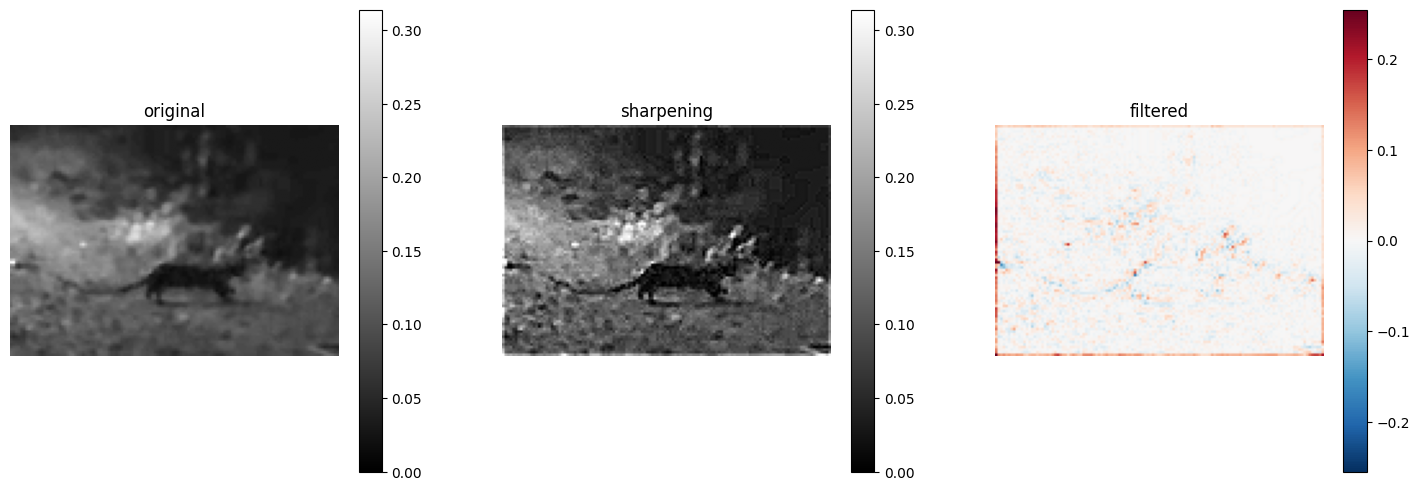

In [73]:
# 사진이 어둡고 해상도가 낮아 원래 노이즈가 많은 편이라,
# 경계를 너무 강하게 잡으면 노이즈까지 같이 커질 것 같다고 판단했다.
# 그래서 w는 대각선까지 포함하는 8방향 Laplacian kernel 대신,
# 효과가 상대적으로 완만한 4방향 Laplacian kernel을 사용했다.
# c는 값을 바꿔가며 결과를 비교했다.
# c가 작을 때는 원본과 거의 차이가 없었다.
# c가 클 때(예: 30)는 경계뿐 아니라 노이즈까지 과하게 강조되어 사진이 오히려 지저분해졌다.
# c=1일 때 고양이의 윤곽과 풀숲이 또렷해지면서도 노이즈가 크게 거슬리지 않아 c=1로 정했다.
# 원본과 결과를 같은 기준으로 비교하기 위해 두 영상 모두
# vmin=0, vmax=f.max()로 표시 범위를 맞췄다.


f = io.imread('/content/blurred_picture.jpg',as_gray=True)[::2,::2]

w = np.array([[0,-1,0],[-1,4,-1],[0,-1,0]])
y = signal.convolve2d(f,w,mode='same')
c = 1
g = f + c*(y)
plt.figure(figsize=(18,6))
plt.subplot(131)
plt.imshow(f, cmap='gray', vmin=0, vmax=f.max())   # original
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(132)
plt.imshow(g, cmap='gray', vmin=0, vmax=f.max())   # sharpening
plt.colorbar()
plt.axis('off')
plt.title('sharpening')
plt.subplot(133)
plt.imshow(y,cmap='RdBu_r',vmin=-0.5*np.max(np.abs(y)),vmax=0.5*np.max(np.abs(y)))
plt.colorbar()
plt.axis('off')
plt.title('filtered')
plt.show()